<a href="https://colab.research.google.com/github/Muhmmad-Salar-Farooq/Helmet-Detection-YOLO/blob/main/Copy_of_helmet_proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.5 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
import os
from ultralytics import YOLO
import cv2
from google.colab import files
from IPython.display import HTML,Image, display
from base64 import b64encode
import glob

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:


dataset_path = "/content/drive/MyDrive/helmet labled dataset/data"
print(os.listdir(dataset_path))

['data.yaml', 'vaid', 'train', 'test']


In [ ]:


train_images = os.listdir(dataset_path + "/train/images")
train_labels = os.listdir(dataset_path + "/train/labels")

print("Train Images:", len(train_images))
print("Train Labels:", len(train_labels))

Train Images: 368
Train Labels: 367


In [ ]:
model = YOLO("yolov8n.pt")
print("YOLOv8 ready! ✅")

YOLOv8 ready! ✅


In [ ]:
drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/helmet labled dataset/data/data.yaml"

print(data_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/helmet labled dataset/data/data.yaml


In [ ]:
dataset_path = "/content/drive/MyDrive/helmet labled dataset/data"

for folder in ["train/images", "train/labels", "vaid/images", "vaid/labels"]:
    path = os.path.join(dataset_path, folder)
    print(folder, "→", os.path.exists(path))

train/images → True
train/labels → True
vaid/images → True
vaid/labels → True


In [ ]:
model = YOLO("yolov8n.pt")
data_path = "/content/drive/MyDrive/helmet labled dataset/data/data.yml"
print("Model & dataset path ready ✅")

Model & dataset path ready ✅


In [ ]:
data_path = "/content/drive/MyDrive/helmet labled dataset/data/data.yaml"

results = model.train(
    data=data_path,
    epochs=30,
    imgsz=640,
    batch=16,
    name="helmet_detection"
)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/helmet labled dataset/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=he

In [ ]:
model = YOLO("/content/runs/detect/helmet_detection/weights/best.pt")
print("Trained model successfully loaded! 🎯")

Trained model successfully loaded! 🎯


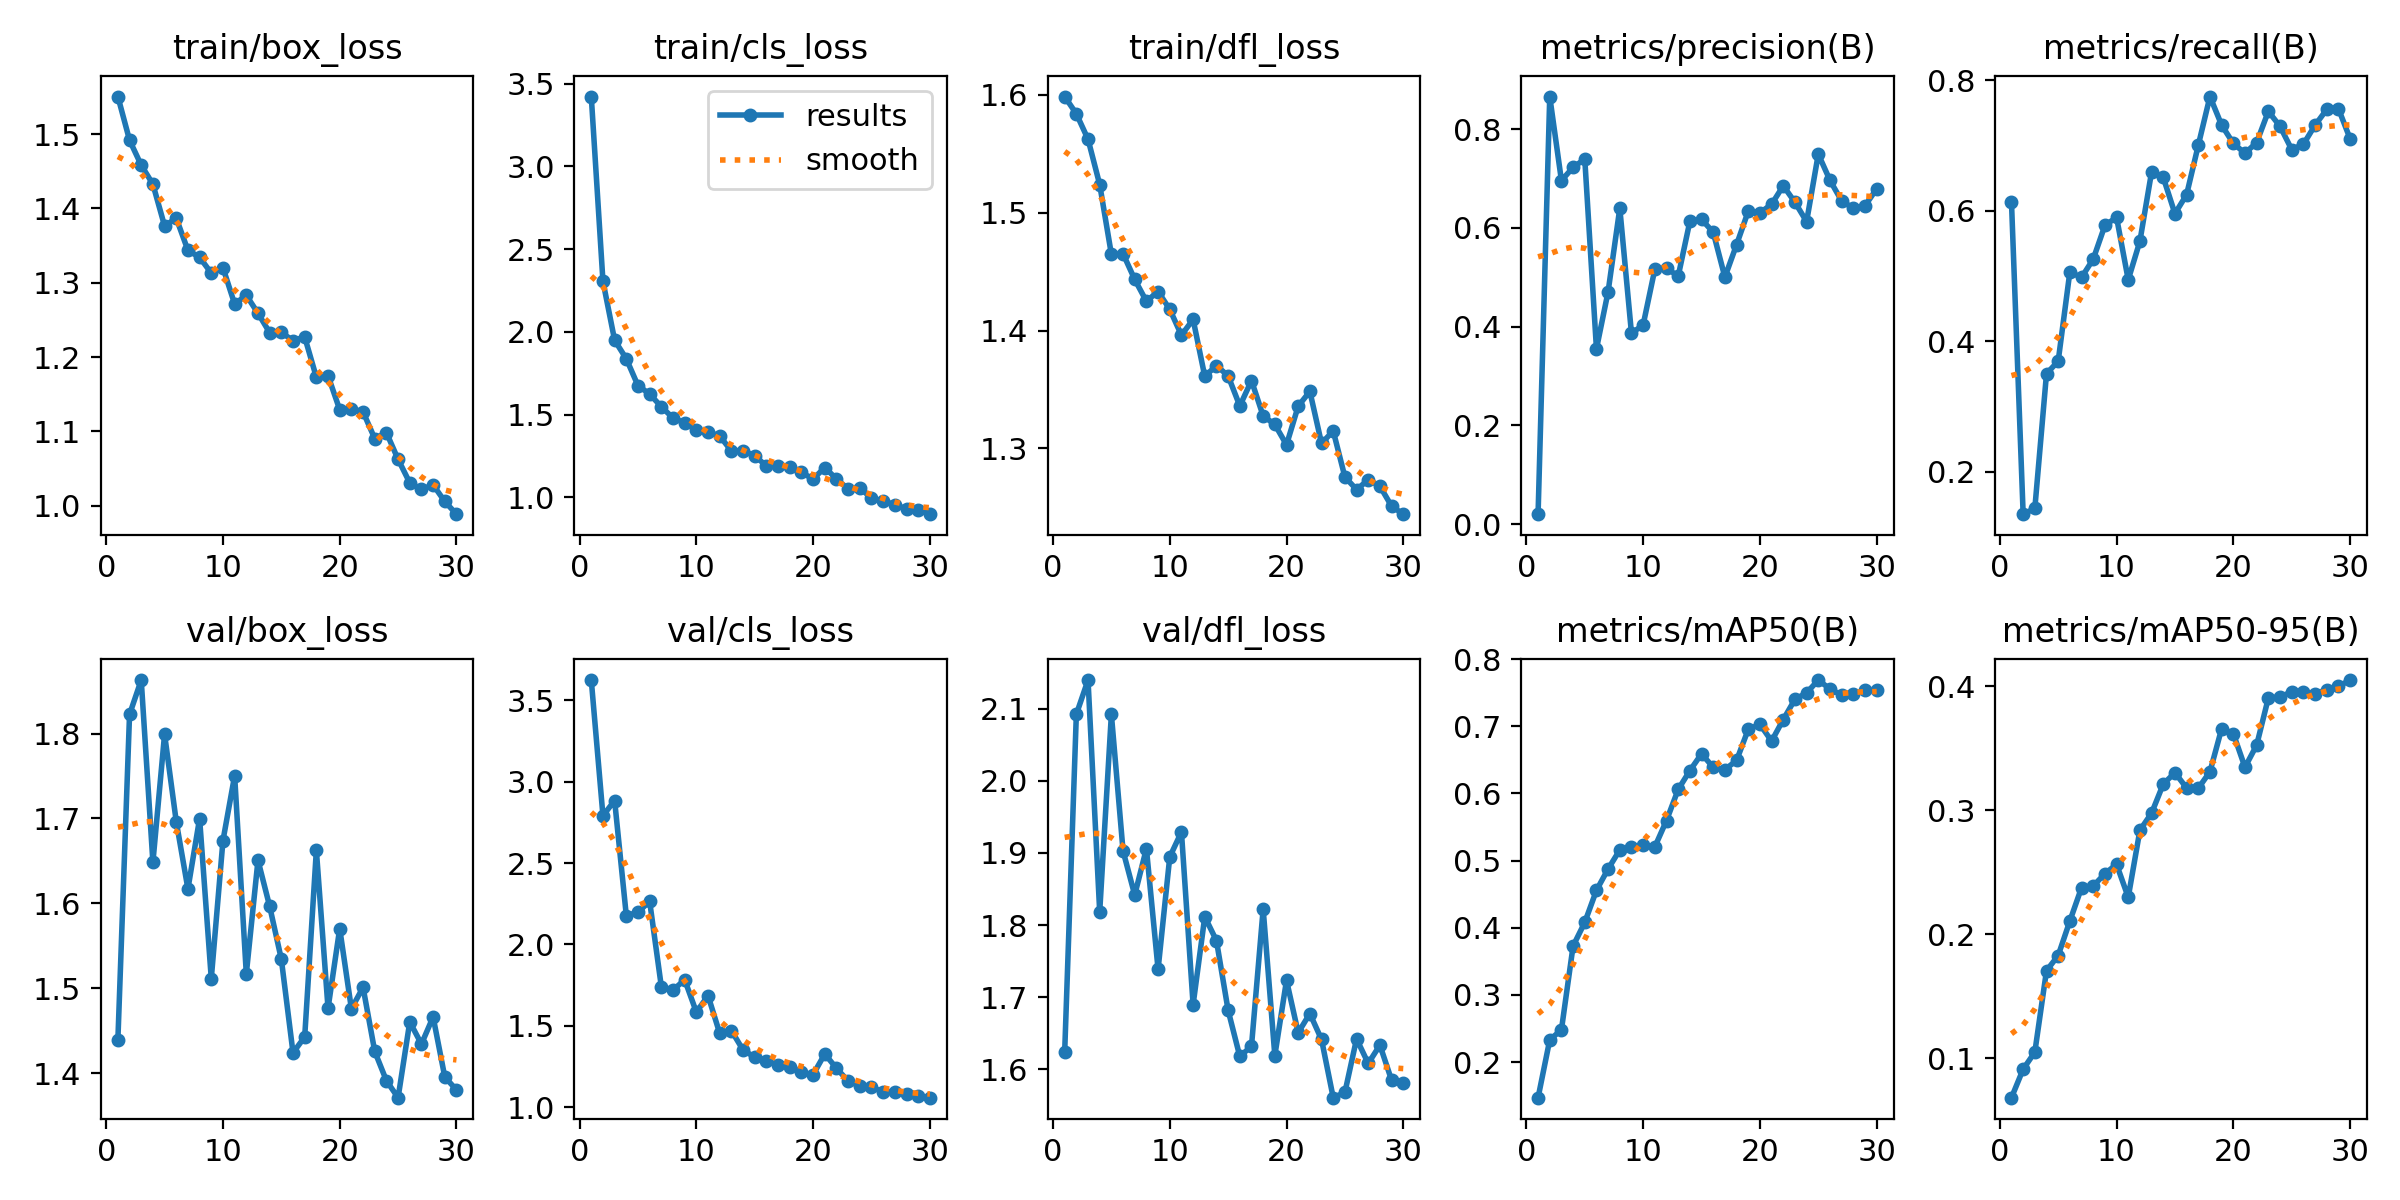

In [ ]:


display(Image(filename="/content/runs/detect/helmet_detection/results.png"))

In [ ]:
model = YOLO("/content/runs/detect/helmet_detection/weights/best.pt")
print("Best model loaded ✅")

Best model loaded ✅


In [ ]:


test_images = glob.glob(
    "/content/drive/MyDrive/helmet labled dataset/data/test/images/*"
)

print("Test images:", len(test_images))
print("First image:", test_images[0])

Test images: 52
First image: /content/drive/MyDrive/helmet labled dataset/data/test/images/ab.jpeg


In [ ]:
results = model.predict(
    source=test_images[0],
    conf=0.25,
    save=True
)

print("Detection complete ✅")


image 1/1 /content/drive/MyDrive/helmet labled dataset/data/test/images/ab.jpeg: 640x640 1 driver_with_helmet, 1 bike, 1 driver, 1 passenger_with_helemt, 1 passenger, 5.9ms
Speed: 2.3ms preprocess, 5.9ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
Detection complete ✅


Results: ['/content/runs/detect/predict/ab.jpg']


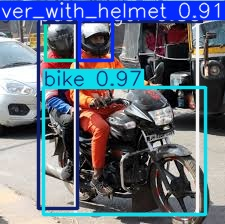

In [ ]:
result_images = glob.glob("/content/runs/detect/predict/*")
print("Results:", result_images)
display(Image(filename=result_images[0]))

In [ ]:
data_path = "/content/drive/MyDrive/helmet labled dataset/data/data.yaml"

metrics = model.val(
    data=data_path,
    imgsz=640
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.117 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 23.5±16.5 MB/s, size: 25.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/MyDrive/helmet labled dataset/data/vaid/labels.cache... 65 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 65/65 18.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.9it/s 2.6s
                   all         65        271      0.684      0.714      0.753      0.405
    driver_with_helmet         44         54      0.683      0.758      0.838      0.432
                  bike         53         63       0.91      0.801      0.898       0.52
                driver         52         59       0.73      0.847      0.842      0.521
 passenger_with_helemt         13    

In [ ]:
# from google.colab import files

# uploaded = files.upload()

Saving download.jpg to download.jpg


In [ ]:
# print(list(uploaded.keys()))

['download.jpg']


In [ ]:
# results = model.predict(
#     source=list(uploaded.keys())[0],
#     conf=0.25,
#     save=False
# )


image 1/1 /content/download.jpg: 480x640 1 bike, 1 driver, 1 driver_without_helmet, 39.0ms
Speed: 3.6ms preprocess, 39.0ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)


array([[[251, 240, 232],
        [252, 241, 233],
        [251, 242, 233],
        ...,
        [254, 252, 251],
        [254, 252, 251],
        [254, 252, 251]],

       [[252, 241, 233],
        [252, 241, 233],
        [252, 243, 234],
        ...,
        [254, 252, 251],
        [254, 252, 251],
        [254, 252, 251]],

       [[252, 241, 233],
        [252, 241, 233],
        [252, 243, 234],
        ...,
        [254, 252, 251],
        [254, 252, 251],
        [254, 252, 251]],

       ...,

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  1,   1,   1],
        [  0,   0,   0],
        [  1,   1,   1]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  1,   1,   1],
        [  0,   0,   0],
        [  1,   1,   1]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  1,   1,   1]]], dtype=uint8)
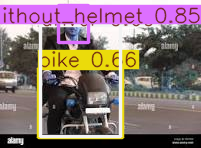

In [ ]:
# display(results[0].plot())

In [ ]:


print("Video file upload karein:")
uploaded_video = files.upload()
video_path = list(uploaded_video.keys())[0]

cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))

output_path = "output_prediction.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

print("Processing video frames...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    results = model.predict(source=frame, conf=0.25, verbose=False)

    annotated_frame = results[0].plot()

    out.write(annotated_frame)
cap.release()
out.release()
cv2.destroyAllWindows()

print("Video processing complete! ✅")
files.download(output_path)

Video file upload karein:


Saving WhatsApp Video 2026-08-10 at 3.52.52 PM.mp4 to WhatsApp Video 2026-08-10 at 3.52.52 PM.mp4
Processing video frames...
Video processing complete! ✅


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>